## Problema - Red de estaciones de transporte con grafos, BFS y DFS

**Instrucción:** completa esta plantilla con tu diseño y desarrollo. Evita incluir soluciones generadas automáticamente.

*(Parcial práctico T2 - 1101)*


Estudiante: Juan Felipe Herrera Puentes

Código: 1000115091

## 1) Descripción del problema **[1 pts]**

Una empresa de transporte urbano quiere representar las conexiones entre sus estaciones. Cada estación es un vértice y cada conexión directa es una arista de un grafo no dirigido.

El programa debe:
- Guardar la red en una **lista de adyacencia** y mostrar cada estación con las estaciones a las que se llega directamente.
- Recorrer la red con **BFS** (usando una cola) y con **DFS** (recursión o pila).
- Permitir elegir cualquier estación inicial y avisar si no existe.
- Encontrar, con BFS, la ruta con **menos conexiones** entre dos estaciones.
- Agregar una estación nueva conectada con al menos dos estaciones existentes.

**Red inicial:** Central, Norte, Museo, Parque, Universidad, Hospital y Terminal, con las conexiones Central-Norte, Central-Museo, Norte-Parque, Norte-Universidad, Museo-Hospital, Universidad-Terminal y Hospital-Terminal.


## 2) Requerimientos **[2 pts]**

**Funcionales**
- RF1. Representar la red con una lista de adyacencia y mostrar cada estación con sus conexiones directas.
- RF2. Ejecutar BFS desde una estación, mostrando el orden de visita y el nivel de cada estación.
- RF3. Ejecutar DFS desde una estación, mostrando el orden de visita.
- RF4. Permitir elegir la estación inicial; si no existe, informar el error.
- RF5. Encontrar con BFS una ruta de menor cantidad de conexiones entre dos estaciones, o indicar que no existe.
- RF6. Registrar una estación nueva conectada con al menos dos estaciones existentes y mostrar la red actualizada.

**No funcionales**
- RNF1. Grafo no dirigido: cada conexión se guarda en ambos sentidos y sin duplicados.
- RNF2. BFS usa una cola; DFS usa recursividad; cada estación se visita una sola vez (lista de visitadas).
- RNF3. No se usan librerías que ya implementen BFS o DFS.
- RNF4. Código Python funcional, con nombres claros y com disponibilidad 24/7.
- RNF5. Mensajes claros ante errores (estación inexistente, sin ruta, menos de dos conexiones).



## 3) Historias de usuario **[2 pts]**

**HU1 – Ver la red**
Como planeador de la empresa, quiero ver cada estación con sus conexiones directas, para entender cómo está armada la red.
*Criterios de aceptación:*
- Si hay conexión Central-Norte, Norte aparece en la lista de Central y Central en la de Norte.

**HU2 – Recorrer la red desde una estación**
Como planeador, quiero recorrer la red con BFS y DFS desde cualquier estación, para ver hasta dónde se puede llegar y en cuántas conexiones.
*Criterios de aceptación:*
- Dada una estación existente, veo el orden BFS con el nivel de cada estación y el orden DFS.
- Cada estación aparece una sola vez en cada recorrido.
- Si la estación no existe, se muestra un error y el programa no se cae.

**HU3 – Encontrar la ruta más corta**
Como pasajero, quiero conocer la ruta con menos conexiones entre mi estación de origen y la de destino, para viajar con menos transbordos.
*Criterios de aceptación:*
- Entre dos estaciones conectadas se muestra una ruta con la menor cantidad de conexiones y su cantidad.
- Si no hay ruta, se indica claramente.

**HU4 – Registrar una estación nueva**
Como administrador, quiero agregar una estación nueva conectada con al menos dos estaciones existentes, para ampliar la red.
*Criterios de aceptación:*
- Con menos de dos conexiones, o con una estación que no existe, el registro se rechaza con un mensaje.
- Si es válido, la red actualizada muestra la conexión en ambos sentidos y se pueden ejecutar de nuevo BFS, DFS y la búsqueda de ruta.


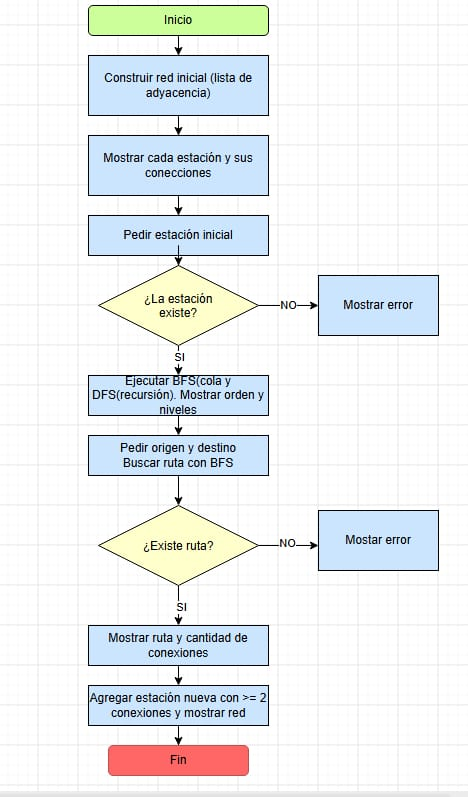

**Descripción del diagrama**
1. Inicio y construcción de la red inicial con lista de adyacencia.
2. Se muestra cada estación con sus conexiones.
3. Se pide la estación inicial y se valida: si no existe se muestra un error; si existe se ejecutan BFS (con cola) y DFS (recursivo) y se muestran los ordenes y los niveles.
4. Se piden origen y destino y se busca la ruta con BFS: si existe se muestra la ruta y la cantidad de conexiones; si no, se informa que no hay ruta.
5. Se agrega una estación nueva con al menos dos conexiones, se muestra la red actualizada y fin.


### 5) Análisis de complejidad **[15 pts]**

**Notación:** n = número de estaciones (vértices), m = número de conexiones (aristas).

**Justificación**
- Cada estación entra una sola vez a la cola (porque se revisa la lista `visitadas`): trabajo proporcional a n.
- La lista de vecinas de cada estación se recorre una sola vez. Como el grafo es no dirigido, cada conexión aparece 2 veces (una en cada lista): se revisan 2m vecinas en total.
- Se cuenta como 1 paso: sacar de la cola, preguntar si una estación ya fue visitada y agregarla.


**Mejor y peor caso**
- **Mejor caso:** la estación inicial no tiene conexiones (o en la ruta, origen = destino). Se saca 1 estación y no se revisa ninguna vecina: **Θ(1)**.
- **Peor caso:** todas las estaciones conectadas con todas, m = n(n − 1)/2. Entonces T(n) = **Θ(n²)**.
- Caso intermedio: una cadena de estaciones (m = n − 1) da T(n) = Θ(n).



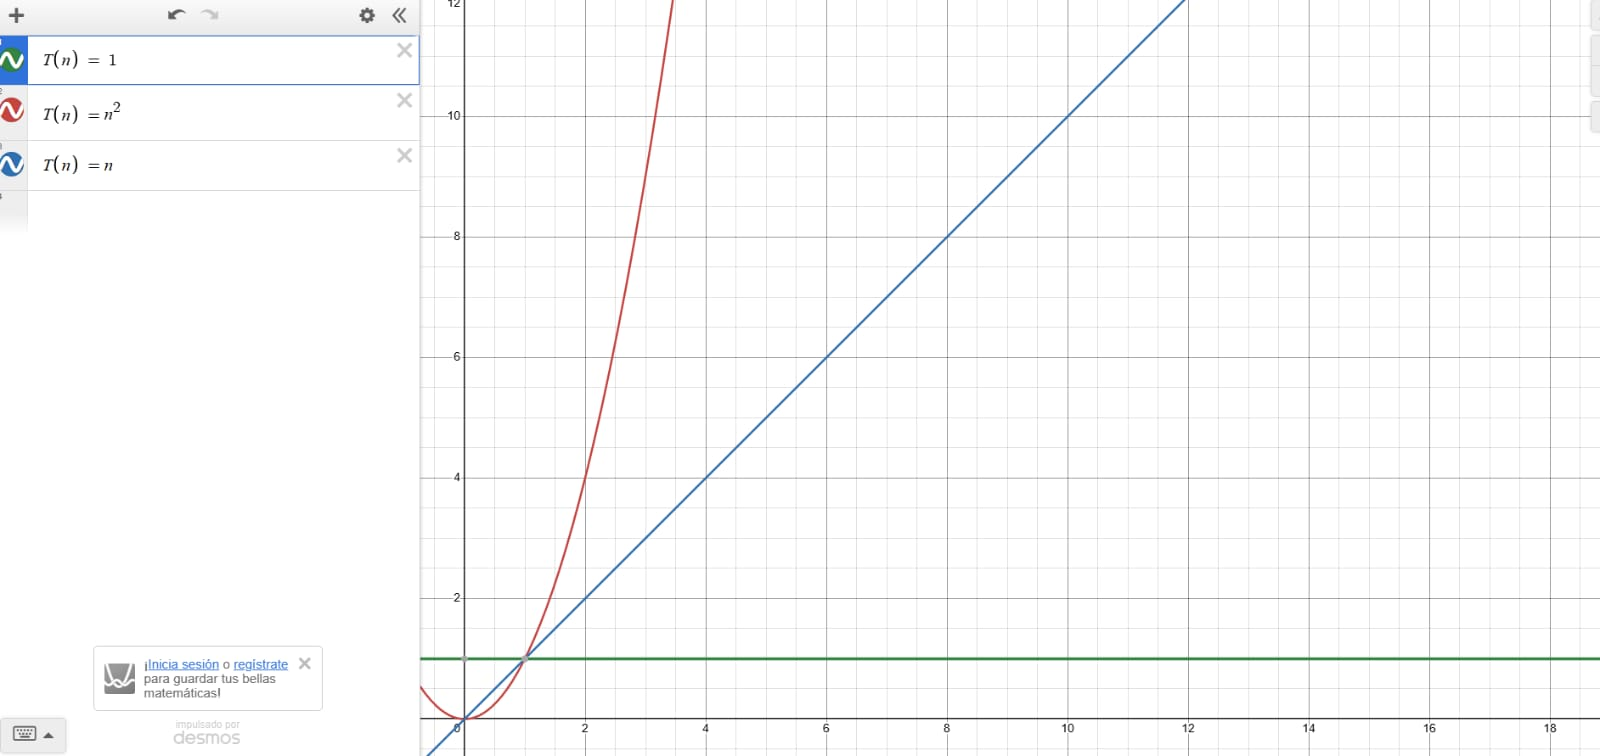

## 6) Código funcional **[15 pts]**
Primero las funciones (Python básico) y después se ejecuta cada punto del parcial.


In [25]:


grafo = {
    "Central": ["Norte", "Museo"],
    "Norte": ["Central", "Parque", "Universidad"],
    "Museo": ["Central", "Hospital"],
    "Parque": ["Norte"],
    "Universidad": ["Norte", "Terminal"],
    "Hospital": ["Museo", "Terminal"],
    "Terminal": ["Universidad", "Hospital"]
}

def mostrar_grafo(grafo):

    print("\nRED DE ESTACIONES")
    for estacion in grafo:
        print(estacion, ":", grafo[estacion])

def bfs(grafo, inicio):
    visitados = [inicio]
    cola = [inicio]
    orden = []
    niveles = {inicio: 0}

    while len(cola) > 0:
        estacion = cola.pop(0)
        orden.append(estacion)

        for vecino in grafo[estacion]:
            if vecino not in visitados:
                visitados.append(vecino)
                cola.append(vecino)
                niveles[vecino] = niveles[estacion] + 1

    return orden, niveles

def dfs(grafo, estacion, visitados, orden):
    visitados.append(estacion)
    orden.append(estacion)

    for vecino in grafo[estacion]:
        if vecino not in visitados:
            dfs(grafo, vecino, visitados, orden)

def buscar_ruta(grafo, origen, destino):
    visitados = [origen]
    cola = [origen]
    padres = {origen: None}

    while len(cola) > 0:
        estacion = cola.pop(0)
        if estacion == destino:
            break

        for vecino in grafo[estacion]:
            if vecino not in visitados:
                visitados.append(vecino)
                cola.append(vecino)
                padres[vecino] = estacion

    if destino not in padres:
        print("No existe una ruta entre esas estaciones.")
    else:
        ruta = []
        actual = destino
        while actual is not None:
            ruta.append(actual)
            actual = padres[actual]
        ruta.reverse()

        print("Ruta encontrada:", ruta)
        print("Cantidad de conexiones:", len(ruta) - 1)


def agregar_estacion(grafo):
    nueva = input("\nNombre de la nueva estacion: ").strip()
    if nueva == "":
        print("El nombre no puede estar vacio.")
        return

    if nueva in grafo:
        print("Esa estacion ya existe.")
        return

    conexion1 = input("Primera estacion existente para conectar: ").strip()
    conexion2 = input("Segunda estacion existente para conectar: ").strip()

    if conexion1 not in grafo or conexion2 not in grafo:
        print("Error: las dos estaciones deben existir.")
        return

    if conexion1 == conexion2:
        print("Error: debes elegir dos estaciones diferentes.")
        return

    grafo[nueva] = []
    grafo[nueva].append(conexion1)
    grafo[conexion1].append(nueva)
    grafo[nueva].append(conexion2)
    grafo[conexion2].append(nueva)
    print("Estacion agregada correctamente.")


mostrar_grafo(grafo)


print("\nBFS DESDE CENTRAL")
orden_bfs, niveles = bfs(grafo, "Central")
print("Orden de visita:", orden_bfs)

for estacion in niveles:
    print(estacion, "- Nivel:", niveles[estacion])

print("\nDFS DESDE CENTRAL")
visitados = []
orden_dfs = []

dfs(grafo, "Central", visitados, orden_dfs)
print("Orden de visita:", orden_dfs)



print("\nELEGIR ESTACION INICIAL")
inicio = input("Ingrese la estacion inicial: ").strip()

if inicio not in grafo:
    print("Error: esa estacion no existe.")

else:
    orden_bfs, niveles = bfs(grafo, inicio)
    print("BFS desde", inicio, ":", orden_bfs)

    visitados = []
    orden_dfs = []
    dfs(grafo, inicio, visitados, orden_dfs)
    print("DFS desde", inicio, ":", orden_dfs)

print("\nBUSCAR RUTA")
origen = input("Ingrese la estacion de origen: ").strip()
destino = input("Ingrese la estacion de destino: ").strip()

if origen not in grafo or destino not in grafo:
    print("Error: el origen y el destino deben existir.")

else:
    buscar_ruta(grafo, origen, destino)

print("\nAGREGAR UNA NUEVA ESTACION")
agregar_estacion(grafo)

mostrar_grafo(grafo)

print("\nRECORRIDOS DE LA RED ACTUALIZADA")
inicio = input("Ingrese la estacion inicial para los recorridos: ").strip()

if inicio not in grafo:
    print("Error: esa estacion no existe.")

else:
   orden_bfs, niveles = bfs(grafo, inicio)
   print("BFS:", orden_bfs)
   print("Niveles BFS:")
   for estacion in niveles:
    print(estacion, "- Nivel:", niveles[estacion])

    visitados = []
    orden_dfs = []

    dfs(grafo, inicio, visitados, orden_dfs)
    print("DFS:", orden_dfs)

print("\nBUSCAR RUTA EN LA RED ACTUALIZADA")
origen = input("Ingrese el origen: ").strip()
destino = input("Ingrese el destino: ").strip()
if origen not in grafo or destino not in grafo:
    print("Error: el origen y el destino deben existir.")
else:
    buscar_ruta(grafo, origen, destino)
 
opcion = ""
 
while opcion != "0":
    print("\n===== MENU DE LA RED DE TRANSPORTE =====")
    print("1. Mostrar la red de estaciones")
    print("2. Ejecutar BFS y mostrar niveles")
    print("3. Ejecutar DFS")
    print("4. Buscar la ruta mas corta")
    print("5. Agregar una nueva estacion")
    print("0. Salir")
 
    opcion = input("Seleccione una opcion: ")
 
    if opcion == "1":
        mostrar_grafo(grafo)
 
    elif opcion == "2":
        inicio = input("Estacion inicial para BFS: ").strip()
 
        if inicio in grafo:
            orden, niveles = bfs(grafo, inicio)
            print("Orden BFS:", orden)
 
            for estacion in niveles:
                print(estacion, "- Nivel:", niveles[estacion])
        else:
            print("Error: esa estacion no existe.")
 
    elif opcion == "3":
        inicio = input("Estacion inicial para DFS: ").strip()
 
        if inicio in grafo:
            visitados = []
            orden = []
            dfs(grafo, inicio, visitados, orden)
            print("Orden DFS:", orden)
        else:
            print("Error: esa estacion no existe.")
 
    elif opcion == "4":
        origen = input("Estacion de origen: ").strip()
        destino = input("Estacion de destino: ").strip()
 
        if origen in grafo and destino in grafo:
            buscar_ruta(grafo, origen, destino)
        else:
            print("Error: el origen y el destino deben existir.")
 
    elif opcion == "5":
        agregar_estacion(grafo)
        mostrar_grafo(grafo)
 
    elif opcion == "0":
        print("Programa finalizado.")
 
    else:
        print("Opcion incorrecta. Intente nuevamente.")
 





RED DE ESTACIONES
Central : ['Norte', 'Museo']
Norte : ['Central', 'Parque', 'Universidad']
Museo : ['Central', 'Hospital']
Parque : ['Norte']
Universidad : ['Norte', 'Terminal']
Hospital : ['Museo', 'Terminal']
Terminal : ['Universidad', 'Hospital']

BFS DESDE CENTRAL
Orden de visita: ['Central', 'Norte', 'Museo', 'Parque', 'Universidad', 'Hospital', 'Terminal']
Central - Nivel: 0
Norte - Nivel: 1
Museo - Nivel: 1
Parque - Nivel: 2
Universidad - Nivel: 2
Hospital - Nivel: 2
Terminal - Nivel: 3

DFS DESDE CENTRAL
Orden de visita: ['Central', 'Norte', 'Parque', 'Universidad', 'Terminal', 'Hospital', 'Museo']

ELEGIR ESTACION INICIAL
Error: esa estacion no existe.

BUSCAR RUTA
Error: el origen y el destino deben existir.

AGREGAR UNA NUEVA ESTACION
El nombre no puede estar vacio.

RED DE ESTACIONES
Central : ['Norte', 'Museo']
Norte : ['Central', 'Parque', 'Universidad']
Museo : ['Central', 'Hospital']
Parque : ['Norte']
Universidad : ['Norte', 'Terminal']
Hospital : ['Museo', 'Terminal

## 7) Tests aplicados **[15 pts]**
Con `assert` se verifican las condiciones del enunciado: lista de adyacencia, grafo no dirigido, sin conexiones duplicadas, BFS, DFS, estación inexistente, ruta más corta, falta de ruta y agregar estación.


In [26]:

 
# Prueba 1: verificar que existan las siete estaciones iniciales
assert len(grafo) == 7
print("Prueba 1 superada: existen las siete estaciones.")
 
 
# Prueba 2: verificar que las conexiones sean en ambos sentidos
for estacion in grafo:
    for vecino in grafo[estacion]:
        assert estacion in grafo[vecino]
 
print("Prueba 2 superada: las conexiones son bidireccionales.")
 
 
# Prueba 3: verificar que no haya conexiones duplicadas
for estacion in grafo:
    assert len(grafo[estacion]) == len(set(grafo[estacion]))
 
print("Prueba 3 superada: no hay conexiones duplicadas.")
 
 
# Prueba 4: verificar el recorrido BFS desde Central
orden_bfs, niveles = bfs(grafo, "Central")
 
assert len(orden_bfs) == 7
assert len(set(orden_bfs)) == 7
assert niveles["Central"] == 0
assert niveles["Norte"] == 1
assert niveles["Museo"] == 1
assert niveles["Terminal"] == 3
 
print("Prueba 4 superada: BFS visita las estaciones y calcula los niveles.")
 
 
# Prueba 5: verificar el recorrido DFS desde Central
visitados = []
orden_dfs = []
 
dfs(grafo, "Central", visitados, orden_dfs)
 
assert len(orden_dfs) == 7
assert len(set(orden_dfs)) == 7
 
print("Prueba 5 superada: DFS visita cada estación una sola vez.")
 
 
# Prueba 6: verificar la cantidad mínima de conexiones a Terminal
# BFS permite conocer la cantidad de conexiones desde Central.
assert niveles["Terminal"] == 3
 
print("Prueba 6 superada: Terminal está a tres conexiones de Central.")
 
# Mostrar la ruta encontrada por la función del programa
buscar_ruta(grafo, "Central", "Terminal")
 
 
# Prueba 7: comprobar que se detecte una estación inexistente
assert "Aeropuerto" not in grafo
 
print("Prueba 7 superada: se reconoce que Aeropuerto aún no existe.")
 
 
print("\nTODAS LAS PRUEBAS FINALIZARON CORRECTAMENTE.")
 

Prueba 1 superada: existen las siete estaciones.
Prueba 2 superada: las conexiones son bidireccionales.
Prueba 3 superada: no hay conexiones duplicadas.
Prueba 4 superada: BFS visita las estaciones y calcula los niveles.
Prueba 5 superada: DFS visita cada estación una sola vez.
Prueba 6 superada: Terminal está a tres conexiones de Central.
Ruta encontrada: ['Central', 'Norte', 'Universidad', 'Terminal']
Cantidad de conexiones: 3
Prueba 7 superada: se reconoce que Aeropuerto aún no existe.

TODAS LAS PRUEBAS FINALIZARON CORRECTAMENTE.
